# Лабораторная работа 3 (в-26)
## Введение
**Название:** предварительная обработка данных

**Цель:** познакомиться с теоретическими принципами и инструментальными средствами предварительной обработки данных

**Описание показателей:**
- name - модель
- year - год
- selling_price - цена продажи
- km_driven - пробег в километрах
- fuel - тип топлива
- seller_type - тип продавца
- transmission - коробка переключения передач (КПП)
- owner - какой по счёту владелец
## 0. Импортируем необходимые библиотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Загружаем набор данных из файла car_data_3.csv и помещаем его в объект DataFrame

In [2]:
df = pd.read_csv('car_data_3.csv')

## 2. Выведем 5 первых строк

In [3]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000.0,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000.0,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000.0,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000.0,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000.0,Diesel,Individual,Manual,Second Owner


## 3. Методы обнаружения пропущенных значений
### 3.1 Воспользуемся методом .info()

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           4340 non-null   object 
 1   year           4340 non-null   int64  
 2   selling_price  4340 non-null   int64  
 3   km_driven      4282 non-null   float64
 4   fuel           4340 non-null   object 
 5   seller_type    4340 non-null   object 
 6   transmission   4340 non-null   object 
 7   owner          4295 non-null   object 
dtypes: float64(1), int64(2), object(5)
memory usage: 271.4+ KB


### 3.2 .isna() и .sum()
Уже заметны несовпадения, но сделаем их более наглядными при помощи .isna() и .sum()

In [5]:
df.isna().sum()

name              0
year              0
selling_price     0
km_driven        58
fuel              0
seller_type       0
transmission      0
owner            45
dtype: int64

### 3.3 Процентное отсутствие
Посчитаем недостаток при помощи математики

In [6]:
(df.isna().sum() / len(df)).round(4) * 100

name             0.00
year             0.00
selling_price    0.00
km_driven        1.34
fuel             0.00
seller_type      0.00
transmission     0.00
owner            1.04
dtype: float64

### 3.4 Корреляция пропусков

In [7]:
df[['km_driven', 'owner']].isnull().corr()

,km_driven,owner
km_driven,1.000000,0.007896
owner,0.007896,1.000000


Поскольку корреляция близка к 0, можно понять, что пропуск одного признака не влияет на пропуск другого
## 4. Стратегии работы с пропусками
Поскольку существуют две стратегии (удаление и заполнение), создадим два новых дата-фрейма на базе текущего: dfD (dataFrameDelete) и dfF (dataFrameFill)

In [8]:
dfD = df
dfF = df
dfD.info()
print('')
print('_________________')
print('')
dfF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           4340 non-null   object 
 1   year           4340 non-null   int64  
 2   selling_price  4340 non-null   int64  
 3   km_driven      4282 non-null   float64
 4   fuel           4340 non-null   object 
 5   seller_type    4340 non-null   object 
 6   transmission   4340 non-null   object 
 7   owner          4295 non-null   object 
dtypes: float64(1), int64(2), object(5)
memory usage: 271.4+ KB

_________________

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           4340 non-null   object 
 1   year           4340 non-null   int64  
 2   selling_price  4340 non-null   int64  
 3   km_driven      4282 non-null   float64


### 4.1 Удаление пропусков
Как можно заметить, пропуски имеют средний характер (не единичные, но и не огромные, оба пропуска всего на 1% данных). Поэтому удалять столбцы целиком смысла нет, а вот удалить данные строки выглядит совершенно логичным решением

In [9]:
dfD.dropna(axis = 'index', subset = ['owner'], inplace = True)
dfD.dropna(axis = 'index', subset = ['km_driven'], inplace = True)

#убедимся, что неизвестные значения удалились
dfD.isna().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

### 4.2 Заполнение пропусков
Заполнение константами нам не подходит совершенно точно для пробега, заполнить же владельца константой first owner можно (в жизни часто так делают)) ), но это будет некорректно всё же. Поэтому для пробега воспользуемся средним арифметическим, а для владельца используем наиболее частотное значение

In [10]:
dfF['km_driven'] = dfF.km_driven.fillna(dfF.km_driven.mean())
dfF['owner'] = dfF.owner.fillna(dfF.owner.mode())

#убедимся, что неизвестных значений больше нет
dfF.isna().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

## 5. Кодирование категориальных переменных
### 5.1 Получение информации о категориальных переменных в датафрейме
Выведем информацию о датасете ещё раз и узнаем уникальные значения некоторых категориальных переменных:

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4238 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           4238 non-null   object 
 1   year           4238 non-null   int64  
 2   selling_price  4238 non-null   int64  
 3   km_driven      4238 non-null   float64
 4   fuel           4238 non-null   object 
 5   seller_type    4238 non-null   object 
 6   transmission   4238 non-null   object 
 7   owner          4238 non-null   object 
dtypes: float64(1), int64(2), object(5)
memory usage: 298.0+ KB


In [12]:
# используем print(), поскольку без него выводится лишь последний запрос
# применяем print() к последнему показателю тоже,
# чтобы не было пустой строки перед выводом
print(df.fuel.unique())
print(df.seller_type.unique())
print(df.transmission.unique())
print(df.owner.unique())

['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']
['Individual' 'Dealer' 'Trustmark Dealer']
['Manual' 'Automatic']
['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']


Попробуем посчитать количество этих категориальных признаков для дата-фрейма с удалёнными значениями (если некоторые значения и были удалены, то мы будем иметь меньше или равно от реального числа, но точно не нарисуем тех, кого нет):

In [13]:
# используем print() по той же причине, что и выше, но в этот раз
# оставляем последний вывод без строки, поскольку нам нужны пустые разделяющие
# строки из-за большого количества информации
# (по этой же причине добавлены print(''), чтобы разделить вывод визуально
print(dfD.fuel.value_counts())
print('')
print(dfD.seller_type.value_counts())
print('')
print(dfD.transmission.value_counts())
dfD.owner.value_counts()

fuel
Diesel      2107
Petrol      2070
CNG           38
LPG           22
Electric       1
Name: count, dtype: int64

seller_type
Individual          3167
Dealer               973
Trustmark Dealer      98
Name: count, dtype: int64

transmission
Manual       3801
Automatic     437
Name: count, dtype: int64


owner
First Owner             2765
Second Owner            1083
Third Owner              294
Fourth & Above Owner      79
Test Drive Car            17
Name: count, dtype: int64

В данном случае количество уникальных признаков видно на глаз, но по необходимости можно применить метод .value_counts().count(). Выведем категории на графике:

Text(0, 0.5, 'Категории')

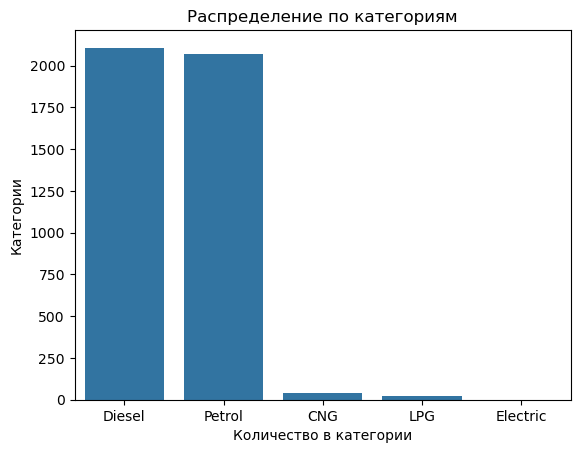

In [14]:
fuel_counts = df.fuel.value_counts()
sns.barplot(x = fuel_counts.index, y = fuel_counts.values)
plt.title('Распределение по категориям')
plt.xlabel('Количество в категории')
plt.ylabel('Категории')

По диаграмме можно заметить, что жители данной местности либо не заботятся об экологии, либо не выставляют на вторичный рынок более экологичные машины.
### 5.2 Преобразование типа данных
У нас имеется 4 категориальных показателя: тип топлива, трансмиссия, продавец и количество владельцев. Для трансмиссии можно применить mapping, поскольку существуют только два значения в датасете (МКПП и АКПП). Для остальных показателей применим OneHotEncoding, поскольку в них больше 2 значений. Кодирование через cat.codes применять не станем, поскольку оно имеет проблемы с интерпретацией (не известно что за что отвечает, если не помнить на память; данная проблема отсутствует при mapping'е).

In [15]:
map_dict = {'Manual': 0, 'Automatic': 1}
dfD['transmission'] = dfD['transmission'].map(map_dict)

# вывел первые 15, чтобы было видно замену значений на 0 и 1
# простой вывод показывал только 0 из-за сильного преобладания МКПП
dfD.head(15)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000.0,Petrol,Individual,0,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000.0,Petrol,Individual,0,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000.0,Diesel,Individual,0,First Owner
3,Datsun RediGO T Option,2017,250000,46000.0,Petrol,Individual,0,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000.0,Diesel,Individual,0,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000.0,Petrol,Individual,0,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000.0,Petrol,Individual,0,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000.0,Petrol,Individual,0,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000.0,Petrol,Individual,0,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000.0,CNG,Individual,0,First Owner


In [16]:
# применяем encoder к трём другим признакам и проверяем вывод
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_array = encoder.fit_transform(dfD[['fuel', 'owner', 'seller_type']])
dfEnc = pd.DataFrame(encoded_array, 
                         columns=encoder.get_feature_names_out(['fuel', 'owner', 'seller_type']))
dfEnc.head()

,fuel_CNG,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer
0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


Присоединяем закодированные признаки к основному дата-фрейму и удаляем исходные признаки:

In [17]:
dfD = dfD.join(dfEnc)
dfD.drop(['owner', 'fuel', 'seller_type', 'owner_Test Drive Car', 
          'fuel_Electric', 'seller_type_Trustmark Dealer'], axis=1, inplace = True)
dfD.head()

,name,year,selling_price,km_driven,transmission,fuel_CNG,fuel_Diesel,fuel_LPG,fuel_Petrol,owner_First Owner,owner_Fourth & Above Owner,owner_Second Owner,owner_Third Owner,seller_type_Dealer,seller_type_Individual
0,Maruti 800 AC,2007,60000,70000.0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
1,Maruti Wagon R LXI Minor,2007,135000,50000.0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
2,Hyundai Verna 1.6 SX,2012,600000,100000.0,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,Datsun RediGO T Option,2017,250000,46000.0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
4,Honda Amaze VX i-DTEC,2014,450000,141000.0,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


Конец лабораторной работы.